<>:38: SyntaxWarning: invalid escape sequence '\s'
<>:38: SyntaxWarning: invalid escape sequence '\s'
C:\Users\Hype AMD\AppData\Local\Temp\ipykernel_3808\268096089.py:38: SyntaxWarning: invalid escape sequence '\s'
  ax3.plot(x, y, label=r"$\mu$ = " + str(i) + ", 1$\sigma$ = 1")


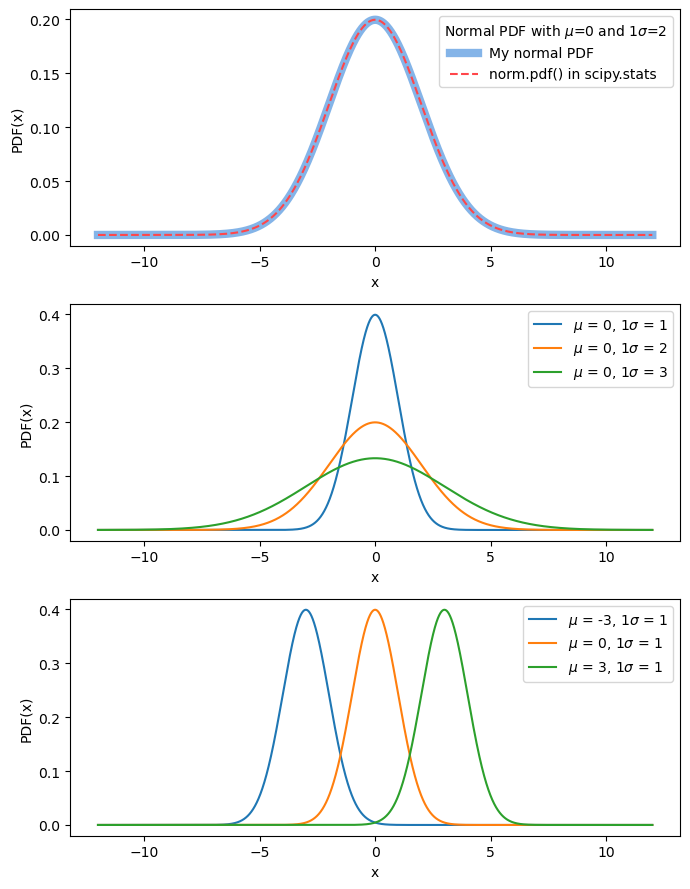

In [ ]:
from scipy.stats import norm  # Mengimpor distribusi normal bawaan dari scipy
import matplotlib.pyplot as plt# Library untuk plotting grafik
import numpy as np  # Library numerik


# I'm going to define my normal PDF...
def normal_pdf(x, mean, std):# Mendefinisikan fungsi PDF normal (rumus manual)
    return 1/(np.sqrt(2*np.pi*std**2))*np.exp(-0.5*((x - mean)**2)/(std**2)) # Rumus distribusi normal (Gaussian)


x = np.arange(-12, 12, .001)# Membuat rentang nilai x dari -12 sampai 12

pdf1 = normal_pdf(x, mean=0, std=2) # Menghitung PDF normal dengan fungsi buatan sendiri

#the built-in norm PDF in scipy.stats
pdf2 = norm.pdf(x, loc=0, scale=2) # PDF normal dari scipy (mean=0, std=2)

fig = plt.figure(figsize=(7,9)) # Membuat figure dengan ukuran tertentu
ax1 = fig.add_subplot(3, 1, 1)# Subplot pertama (3 baris, 1 kolom)
ax1.plot(x,pdf1, color='#84b4e8', linestyle="-", linewidth=6, label="My normal PDF") # Plot hasil fungsi manual
ax1.plot(x,pdf2, color='#ff464a', linestyle="--", label="norm.pdf() in scipy.stats ")# Plot hasil fungsi scipy
ax1.set_xlabel("x")
ax1.set_ylabel("PDF(x)")
ax1.legend(title = r"Normal PDF with $\mu$=0 and 1$\sigma$=2")


ax2 = fig.add_subplot(3, 1, 2)# Subplot kedua
for i in [1, 2, 3]: # Loop untuk variasi standar deviasi
     y = normal_pdf(x,0,i)  # Mean tetap 0, std berubah (1,2,3)
     ax2.plot(x, y, label=r"$\mu$ = 0, 1$\sigma$ = " + str(i))
ax2.set_xlabel("x")
ax2.set_ylabel("PDF(x)")
ax2.legend()

ax3 = fig.add_subplot(3, 1, 3) # Subplot ketiga
for i in [-3, 0, 3]: # Loop untuk variasi mean
     y = normal_pdf(x, i, 1)# Std tetap 1, mean berubah (-3,0,3)
     ax3.plot(x, y, label=r"$\mu$ = " + str(i) + ", 1$\sigma$ = 1")
ax3.set_xlabel("x")
ax3.set_ylabel("PDF(x)")
ax3.legend()

fig.tight_layout() # Mengatur layout agar rapi

In [ ]:
from scipy.stats import norm # Untuk fungsi distribusi normal (PDF)
import numpy as np# Perhitungan numerik
from scipy import special# Untuk fungsi khusus (erf)
from scipy import integrate# Untuk metode integrasi numerik

def integrate_normal(x1, x2, mu, sigma):# Fungsi untuk menghitung luas distribusi normal menggunakan erf (analitik)
    sup = 0.5*((special.erf((x2-mu)/(sigma*np.sqrt(2))))-(special.erf((x1-mu)/(sigma*np.sqrt(2)))))# Rumus integral distribusi normal
    # (special.erf((x2-mu)/(sigma*np.sqrt(2)))) -  # Batas atas
    # (special.erf((x1-mu)/(sigma*np.sqrt(2))))    # Batas bawah

    return sup# Mengembalikan luas area
    
my_mu = 0 # Mean (μ)
my_sigma = 1 # Standar deviasi (σ)

my_x1 = 0 # Batas bawah integral
my_x2 =  my_sigma # Batas atas (σ = 1)

# The expected value is equal to 0.3413...
my_sup = integrate_normal(x1= my_x1, x2= my_x2, mu = my_mu, sigma = my_sigma)# Menghitung luas menggunakan rumus analitik (erf)
 
x = np.arange(my_x1, my_x2, 0.0001) # Membuat titik x untuk integrasi numerik
y =  norm.pdf(x, loc=my_mu, scale= my_sigma) # normal_pdf(x, mean = my_mu, std = my_sigma) # Menghitung nilai PDF normal

sup_trapz = integrate.trapezoid(y,x) # Integrasi numerik dengan metode trapesium
sup_simps = integrate.simpson(y,x)# Integrasi numerik dengan metode Simpson

# Menampilkan hasil
print("Solution Using erf: {:.9f}".format(my_sup))# Hasil analitik
print("Using the trapezoidal rule, trapz: {:.10f}".format(sup_trapz)) # Numerik (trapz)
print("Using the composite Simpson rule, simps: {:.10f}".format(sup_simps))# Numerik (simpson)

'''
Output:
Solution Using erf: 0.341344746
Using the trapezoidal rule, trapz: 0.3413205476
Using the composite Simpson rule, simps: 0.3413205478
'''

Solution Using erf: 0.341344746
Using the trapezoidal rule, trapz: 0.3413205476
Using the composite Simpson rule, simps: 0.3413205478


'\nOutput:\nSolution Using erf: 0.341344746\nUsing the trapezoidal rule, trapz: 0.3413205476\nUsing the composite Simpson rule, simps: 0.3413205478\n'

Sample mean equal to -0.0100
Sample standard deviation equal to 0.9931


'\nOutput: (your results will be sighly different because of the pseudo-random nature of the distribution)\nSample mean equal to -0.0014\nSample standard deviation equal to 1.0014\n'

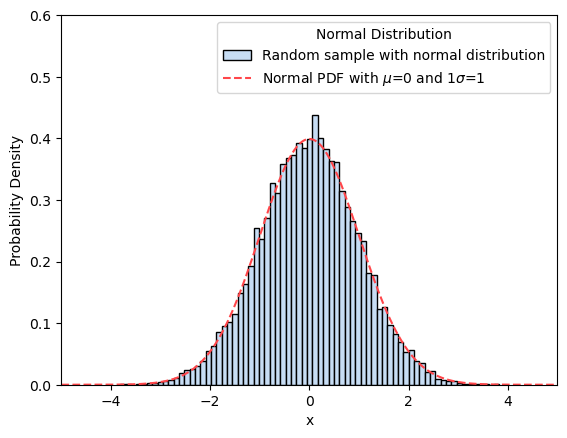

In [ ]:
import numpy as np  # Library untuk perhitungan numerik
from scipy.stats import norm # Untuk distribusi normal (PDF)
import matplotlib.pyplot as plt  # Untuk membuat grafik

mu = 0 # mean  # Mean (rata-rata)
sigma = 1 # standard deviation # Standar deviasi
normal_sample = np.random.normal(mu, sigma, 15000)# Membuat 15.000 data acak dengan distribusi normal (μ=0, σ=1)

# plot the histogram of the sample distribution
fig, ax = plt.subplots()# Membuat histogram distribusi data
ax.hist(normal_sample, bins='auto', density=True, color='#c7ddf4', edgecolor='#000000', label='Random sample with normal distribution')
# bins='auto' → jumlah batang otomatis
# density=True → agar histogram berbentuk PDF (ter-normalisasi)

# probability density function (Membuat kurva PDF teoritis)
x = np.arange(-5,5, 0.01) # Rentang nilai x
normal_pdf = norm.pdf(x, loc= mu, scale = sigma) # Menghitung PDF normal (teoritis)
ax.plot(x, normal_pdf, color='#ff464a', linewidth=1.5, linestyle='--', label=r'Normal PDF with $\mu$=0 and 1$\sigma$=1') # Plot kurva PDF di atas histogram
ax.legend(title='Normal Distribution')
ax.set_xlabel('x')
ax.set_ylabel('Probability Density')
ax.set_xlim(-5,5)
ax.set_ylim(0,0.6)

# Descriptive statistics
aritmetic_mean = normal_sample.mean() # Menghitung rata-rata sampel
standard_deviation = normal_sample.std() # Menghitung standar deviasi sampel

#menampilkan hasil
print('Sample mean equal to {:.4f}'.format(aritmetic_mean))# menampilkan rata-rata sampel (mean) dengan 4 angka di belakang koma
print('Sample standard deviation equal to {:.4f}'.format(standard_deviation))  # menampilkan simpangan baku (standar deviasi) dengan 4 angka di belakang koma

'''
Output: (your results will be sighly different because of the pseudo-random nature of the distribution)
Sample mean equal to -0.0014
Sample standard deviation equal to 1.0014
'''




Expected mean: 0 - Calculated mean: 0.0
Expected std.dev.: 0.5 - Calculated std.dev.: 0.501
Expected mean: 0.5 - Calculated mean: 0.501
Expected std.dev.: 0.4 - Calculated std.dev.: 0.404
Expected mean: 1 - Calculated mean: 1.002
Expected std.dev.: 0.3 - Calculated std.dev.: 0.3


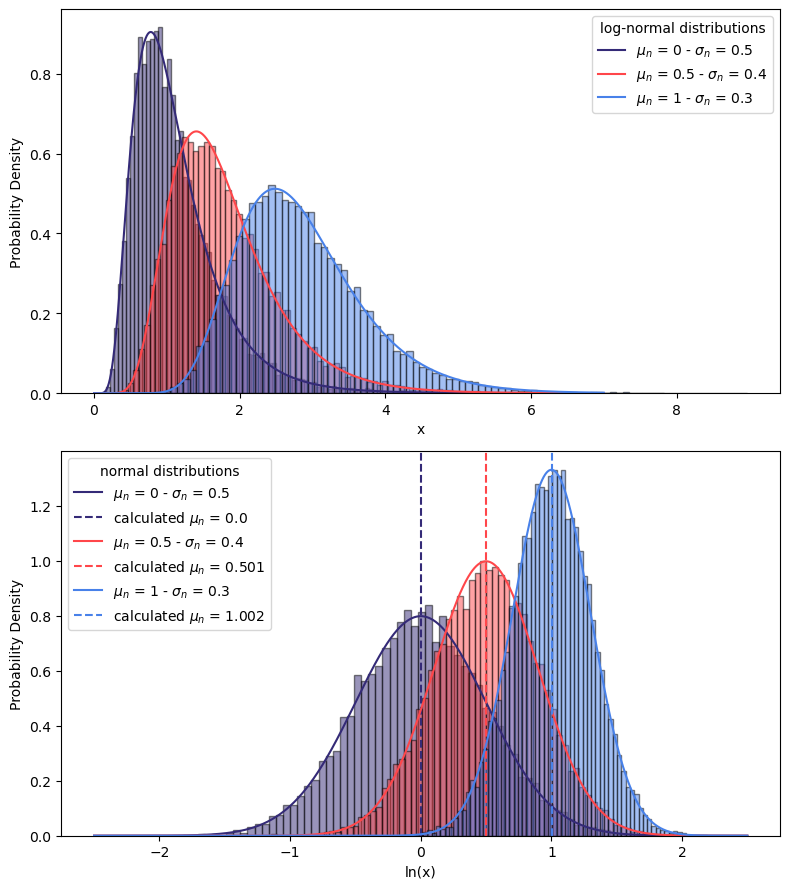

In [ ]:
import matplotlib.pyplot as plt # import library untuk membuat grafik
import numpy as np # import library untuk operasi numerik
from scipy.stats import norm, lognorm# import distribusi normal & log-normal

colors = ['#342a77', '#ff464a', '#4881e9'] # daftar warna untuk plot
normal_mu = [0,0.5,1]# nilai mean (μ) untuk distribusi normal
normal_sigma = [0.5,0.4,0.3]# nilai standar deviasi (σ)
x = np.arange(0.001, 7, .001) # for the log-normal PDF  # range x untuk PDF log-normal
x1 = np.arange(-2.5, 2.5, .001)  # for the normal PDF  # range x untuk PDF normal

fig, (ax1, ax2) = plt.subplots(nrows = 2, ncols = 1, figsize = (8,9)) # membuat 2 subplot (atas & bawah)

for mu_n, sigma_n, color in zip(normal_mu, normal_sigma, colors):   
     lognorm_pdf = lognorm.pdf(x, s=sigma_n, scale=np.exp(mu_n)) # menghitung PDF distribusi log-normal
     r = lognorm.rvs(s=sigma_n, scale=np.exp(mu_n), size=15000)  # generate 15000 data acak dari distribusi log-normal
     ax1.plot(x, lognorm_pdf, color=color, label=r"$\mu_n$ = " + str(mu_n) + r" - $\sigma_n$ = " + str(sigma_n)) # plot kurva PDF log-normal
     ax1.hist(r, bins='auto', density=True, color=color, edgecolor='#000000', alpha=0.5)# histogram data log-normal
     logr= np.log(r)# transformasi log (agar jadi distribusi normal)
     normal_pdf = norm.pdf(x1, loc= mu_n, scale = sigma_n) # menghitung PDF distribusi normal
     ax2.plot(x1, normal_pdf, color=color, label=r"$\mu_n$ = " + str(mu_n) + r" - $\sigma_n$ = " + str(sigma_n))  # plot kurva PDF normal
     ax2.hist(logr, bins='auto', density=True, color=color, edgecolor='#000000', alpha=0.5) # histogram data hasil log (harus mendekati normal)
     my_mu = logr.mean() # menghitung rata-rata dari data log
     ax2.axvline(x=my_mu, color=color, linestyle="--", label=r"calculated $\mu_n$ = " + str(round(my_mu,3))) # garis vertikal untuk mean hasil perhitungan
     my_sigma = logr.std()# menghitung standar deviasi dari data log
     print("Expected mean: " + str(mu_n) + " - Calculated mean: " + str(round(my_mu,3))) # menampilkan perbandingan mean teoritis vs hasil
     print("Expected std.dev.: " + str(sigma_n) + " - Calculated std.dev.: " + str(round(my_sigma,3))) # menampilkan perbandingan standar deviasi teoritis vs hasil
     
ax1.legend(title="log-normal distributions")    # menampilkan legenda plot atas
ax1.set_xlabel('x')  
ax1.set_ylabel('Probability Density')  
ax2.legend(title="normal distributions")  # legenda plot bawah
ax2.set_xlabel('ln(x)') 
ax2.set_ylabel('Probability Density')  

fig.tight_layout()# merapikan tata letak agar tidak saling tumpang tindih







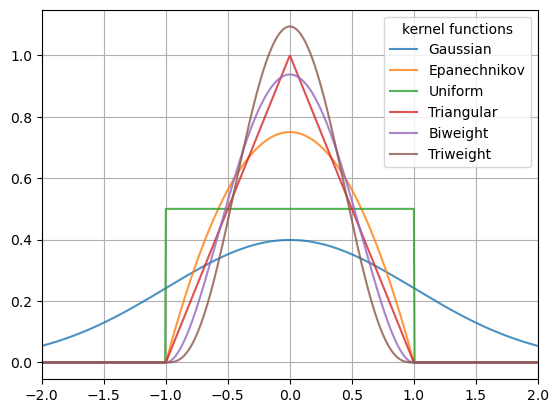

In [ ]:
from statsmodels.nonparametric.kde import KDEUnivariate # import KDE untuk estimasi distribusi non-parametrik
import matplotlib.pyplot as plt# import library plotting
import numpy as np  # import library numerik

kernels = ['gau', 'epa', 'uni', 'tri', 'biw', 'triw']  # jenis-jenis kernel
kernels_names = ['Gaussian', 'Epanechnikov', 'Uniform', 'Triangular', 'Biweight', 'Triweight']# nama lengkap kernel untuk label
positions = np.arange(1,9,1) # array posisi (dipakai untuk iterasi, meskipun tidak terlalu berpengaruh di sini)

fig, ax = plt.subplots() # membuat area plot

for kernel, kernel_name, pos in zip(kernels, kernels_names, positions):# loop tiap jenis kernel

    # kernels
    kde = KDEUnivariate([0]) # membuat objek KDE dengan data titik tunggal (0)
    kde.fit(kernel= kernel, bw=1,  fft=False, gridsize=2**10)
    # melakukan fitting KDE:
    # kernel → jenis fungsi kernel
    # bw=1 → bandwidth (lebar smoothing)
    # fft=False → tidak pakai Fast Fourier Transform
    # gridsize=2**10 → jumlah titik grid (resolusi tinggi)
    ax.plot(kde.support, kde.density, label = kernel_name, linewidth=1.5, alpha=0.8) # plot fungsi kernel (support = sumbu x, density = nilai fungsi)

ax.set_xlim(-2,2)# membatasi tampilan sumbu x dari -2 sampai 2
ax.grid()# menampilkan grid pada plot
ax.legend(title='kernel functions') # menampilkan legenda dengan judul


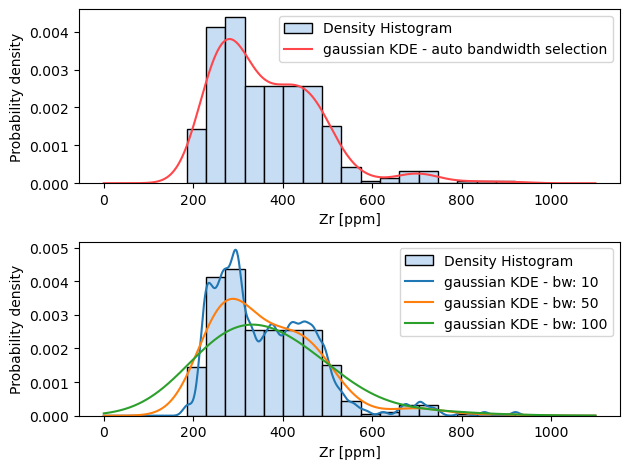

In [ ]:
from statsmodels.nonparametric.kde import KDEUnivariate# import KDE untuk estimasi distribusi
import pandas as pd# import pandas untuk membaca data
import numpy as np# import numpy untuk operasi numerik
import matplotlib.pyplot as plt# import matplotlib untuk plotting

my_dataset = pd.read_excel('Smith_glass_post_NYT_data.xlsx', sheet_name='Supp_traces') # membaca file Excel pada sheet 'Supp_traces'

x = my_dataset.Zr # mengambil kolom Zr sebagai data utama
x_eval = np.arange(0, 1100, 1)# range nilai x untuk evaluasi KDE

fig = plt.figure()# membuat figure kosong

ax1 = fig.add_subplot(2, 1, 1)# subplot pertama (baris 1)
# Density Histogram
ax1.hist(x, bins='auto', density=True, label='Density Histogram', color='#c7ddf4', edgecolor='#000000') # membuat histogram dengan normalisasi (density=True)
kde = KDEUnivariate(x)  # membuat objek KDE dari data x
kde.fit() # fitting KDE dengan bandwidth otomatis
my_kde = kde.evaluate(x_eval)# evaluasi nilai KDE pada x_eval
ax1.plot(x_eval, my_kde, linewidth=1.5, color='#ff464a', label='gaussian KDE - auto bandwidth selection') # plot kurva KDE hasil fitting otomatis
ax1.set_xlabel('Zr [ppm]') # label sumbu x
ax1.set_ylabel('Probability density')
ax1.legend()

ax2 = fig.add_subplot(2, 1, 2) # subplot kedua (baris 2)
# Density Histogram
ax2.hist(x, bins= "auto", density = True, label='Density Histogram', color='#c7ddf4', edgecolor='#000000')  # histogram data yang sama untuk perbandingan

# KDE
# Effect of bandwidth 
for my_bw in [10,50,100]:# mencoba beberapa nilai bandwidth

    kde = KDEUnivariate(x) # membuat objek KDE baru
    kde.fit(bw = my_bw) # fitting KDE dengan bandwidth tertentu
    
    my_kde = kde.evaluate(x_eval)# evaluasi KDE
    ax2.plot(x_eval, my_kde, linewidth = 1.5, label='gaussian KDE - bw: ' + str(my_bw)) # plot hasil KDE dengan bandwidth berbeda
    
ax2.set_xlabel('Zr [ppm]') 
ax2.set_ylabel('Probability density')
ax2.legend()

fig.tight_layout() # merapikan layout agar tidak tumpang tindih

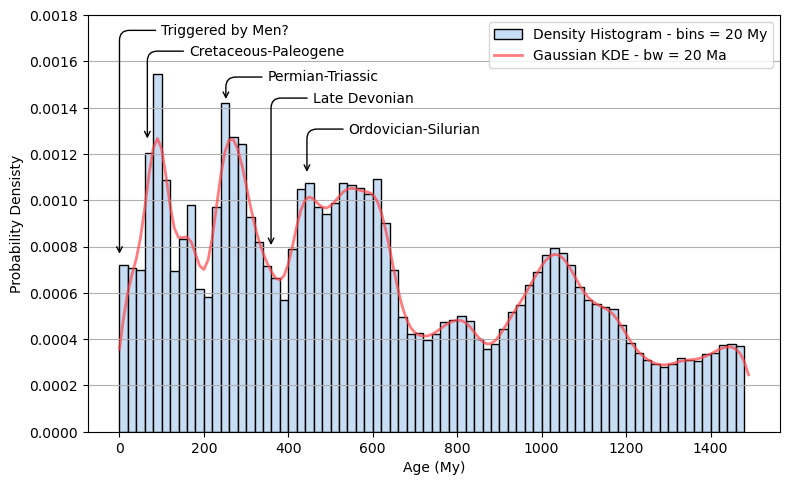

In [ ]:
import pandas as pd # import pandas untuk membaca dan mengolah data
import matplotlib.pyplot as plt # import matplotlib untuk membuat grafik
import numpy as np # import numpy untuk operasi numerik
from statsmodels.nonparametric.kde import KDEUnivariate # import KDE untuk estimasi distribusi

# import Zircon data from Puetz (2010)        
my_data = pd.read_excel('1-s2.0-S1674987117302141-mmc1.xlsx', sheet_name='Data') # membaca file Excel pada sheet 'Data'
my_data = my_data[(my_data.age206Pb_238U>0)&(my_data.age206Pb_238U<1500)] # memfilter data umur antara 0 dan 1500
my_sample = my_data.age206Pb_238U # mengambil kolom umur sebagai sampel

# Plot the Density Histogram
fig, ax = plt.subplots(figsize=(8,5))# membuat figure dan axis
bins = np.arange(0,1500,20) # membuat interval histogram setiap 20 satuan (My)
ax.hist(my_sample, bins, color='#c7ddf4', edgecolor='k', density=True, label='Density Histogram - bins = 20 My') # membuat histogram dengan normalisasi (density=True)

# Compute and plot the KDE
age_eval = np.arange(0,1500,10) # range nilai untuk evaluasi KDE
kde = KDEUnivariate(my_sample) # membuat objek KDE
kde.fit(bw=20) # fitting KDE dengan bandwidth 20
pdf = kde.evaluate(age_eval) # menghitung nilai PDF KDE
ax.plot(age_eval, pdf, label ='Gaussian KDE - bw = 20 Ma', linewidth=2, alpha=0.7, color='#ff464a') # plot kurva KDE

# Adjust diagram parameters
ax.set_ylim(0,0.0018) # mengatur batas sumbu y
ax.set_xlabel('Age (My)')
ax.set_ylabel('Probability Densisty')
ax.legend()
ax.grid(axis='y')  # menampilkan grid pada sumbu y

# Plot mass extinction annotations
mass_extinction_age = [444, 359, 252, 66, 0] # daftar umur kejadian kepunahan massal
pdf_mass_extinction_age = kde.evaluate(mass_extinction_age)# menghitung nilai PDF pada titik kepunahan
mass_extincyion_name = ["Ordovician-Silurian", "Late Devonian", "Permian-Triassic", "Cretaceous-Paleogene", "Triggered by Men?"] # nama-nama peristiwa kepunahan
y_offsets = [0.0001, 0.0001, 0.0002, 0.0002, 0.0004] # offset posisi panah pada sumbu y
y_texts = [30, 105, 15, 62, 160] # posisi teks vertikal (offset)
x_texts = [30, 30, 30, 30, 30] # posisi teks horizontal (offset)

for x, y, name, x_text, y_text, y_offset in zip(mass_extinction_age, pdf_mass_extinction_age, mass_extincyion_name, x_texts, y_texts, y_offsets):
    ax.annotate(name, xy=(x, y + y_offset), xycoords='data',  # menambahkan anotasi (teks + panah) pada grafik
    xytext=(x_text, y_text), textcoords='offset points', # menentukan posisi teks relatif terhadap titik
    arrowprops=dict(arrowstyle="->",
    connectionstyle="angle, angleA=0, angleB=90, rad=10"))  # mengatur bentuk panah anotasi
 
fig.tight_layout() # merapikan layout agar tidak tumpang tindih

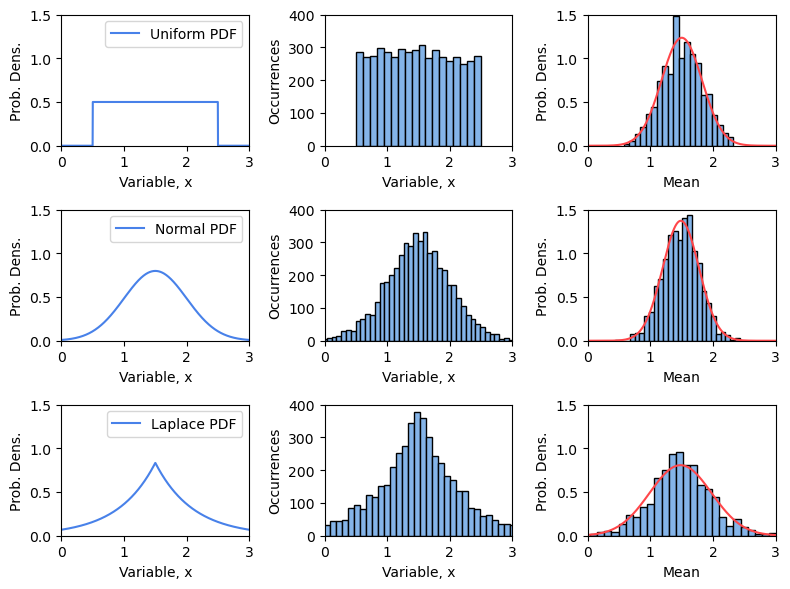

In [ ]:
import numpy as np  # import numpy untuk operasi numerik
import scipy.stats as stats# import distribusi statistik dari scipy 
import matplotlib.pyplot as plt # import matplotlib untuk plotting

fig = plt.figure(figsize=(8,6)) # membuat figure dengan ukuran 8x6

dists = [stats.uniform(loc=0.5, scale=2), stats.norm(loc=1.5, scale=0.5), stats.laplace(loc=1.5, scale=0.6)]
# dists = [stats.uniform(loc=0.5, scale=2),   # distribusi Uniform (mulai 0.5, panjang 2)
# stats.norm(loc=1.5, scale=0.5),    # distribusi Normal (mean=1.5, std=0.5)
# stats.laplace(loc=1.5, scale=0.6)] # distribusi Laplace

names = ['Uniform', 'Normal', 'Laplace'] # nama distribusi untuk label
x = np.linspace(0,3,1000)  # range nilai x untuk plot

for i, (dist, name) in enumerate(zip(dists, names)): # loop tiap distribusi
    
    # Probability Density Function (pdf)
    pdf = dist.pdf(x) # menghitung nilai PDF
    ax1 = fig.add_subplot(3, 3, 3*i+1)  # subplot kolom pertama (PDF)
    ax1.plot(x, pdf, color='#4881e9', label= name + ' PDF') # plot kurva PDF
    ax1.set_xlim(0,3) # batas sumbu x
    ax1.set_ylim(0,1.5)# batas sumbu y
    ax1.set_xlabel('Variable, x')
    ax1.set_ylabel('Prob. Dens.')
    ax1.legend()
    
    #Distribution (rnd) of the Random Variable based on the selected pdf
    rnd = dist.rvs(size=5000)# generate 5000 data acak dari distribusi
    ax2 = fig.add_subplot(3, 3, 3*i+2) # subplot kolom kedua (histogram data)
    ax2.hist(rnd, bins='auto', color='#84b4e8', edgecolor='#000000')  # histogram data acak
    ax2.set_xlim(0,3)  # batas sumbu x
    ax2.set_ylim(0,400)  # batas sumbu y
    ax2.set_xlabel('Variable, x')
    ax2.set_ylabel('Occurrences')
    
    ax3 = fig.add_subplot(3, 3, 3*i+3)  # subplot kolom ketiga (distribusi mean)
    mean_dist = []# list untuk menyimpan rata-rata sampel 
    for _ in range(1000):   # ulangi 1000 kali
        mean_dist.append(dist.rvs(size=3).mean()) # ambil 3 sampel acak lalu hitung mean-nya
    mean_dist = np.array(mean_dist)  # ubah list ke array numpy
    ax3.hist(mean_dist, density=True, bins='auto',  color='#84b4e8', edgecolor='#000000')  # histogram distribusi mean (dinormalisasi)
    normal = stats.norm(loc= mean_dist.mean(), scale= mean_dist.std()) # membuat distribusi normal berdasarkan mean & std dari mean_dist
    ax3.plot(x, normal.pdf(x), color='#ff464a') # plot kurva normal (aproksimasi dari central limit theorem)
    ax3.set_xlim(0,3)  # batas sumbu x
    ax3.set_ylim(0,1.5)  # batas sumbu y
    ax3.set_xlabel('Mean')
    ax3.set_ylabel('Prob. Dens.')
    
fig.tight_layout()# merapikan layout agar tidak tumpang tindih